# ライブラリインポート

In [ ]:
!pip install segmentation-models-pytorch

from google.colab import drive
import torch
import torch.optim as optim
import torch.nn as nn
import torch.nn.functional as F

import os
import cv2
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
import torchvision
from torchvision.datasets import OxfordIIITPet
from torchvision.transforms import v2
import segmentation_models_pytorch as smp
import numpy as np
import matplotlib.pyplot as plt

# ドライブのマウントおよびGPU環境設定

In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


# データセットのダウンロード・前処理

In [ ]:
# 画像用前処理
img_transforms = v2.Compose([
    v2.Resize((256, 256)),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True)
])

# マスク用前処理
mask_transforms = v2.Compose([
    v2.Resize((256, 256)),
    v2.ToImage(),
    v2.Lambda(lambda x: (x > 1).float()) # 1（犬・猫）,2（背景）,3（境界） -> 犬・猫を0,それ以外を1に変換
])

# データセット作成
tv_dataset = OxfordIIITPet(
    root="data",
    split="trainval",
    target_types="segmentation",
    download=True,
    transform=img_transforms,
    target_transform=mask_transforms
)

tv_val_dataset = OxfordIIITPet(
    root="data",
    split="test",
    target_types="segmentation",
    download=True,
    transform=img_transforms,
    target_transform=mask_transforms
)

In [ ]:
try:
    img, mask = tv_dataset[0]
    print(f"Image type: {type(img)}")
    print(f"Image shape: {img.shape}") # [3, 256, 256]
    print(f"Mask shape: {mask.shape}")   # [1, 256, 256]
    print(f"Mask unique values: {torch.unique(mask)}")
except Exception as e:
    print(f"Error: {e}")

Image type: <class 'torchvision.tv_tensors._image.Image'>
Image shape: torch.Size([3, 256, 256])
Mask shape: torch.Size([1, 256, 256])
Mask unique values: tensor([0., 1.])


In [ ]:
print("学習用の画像枚数：", len(tv_dataset))
print("バリデーション用の画像枚数：", len(tv_val_dataset))

学習用の画像枚数： 3680
バリデーション用の画像枚数： 3669


# データローダの作成

In [ ]:
train_loader = DataLoader(
    tv_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=4,
)

val_loader = DataLoader(
    tv_val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=4,
)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


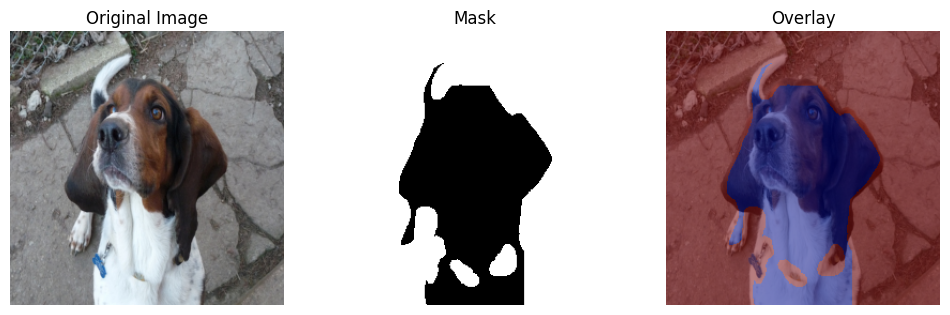

In [ ]:
def visualize_sample(loader):
    # DataLoaderから最初の1バッチ分を取得
    images, masks = next(iter(loader))

    # numpy形式に変換 (C, H, W) -> (H, W, C)
    img = images[0].permute(1, 2, 0).numpy()
    mask = masks[0].squeeze().numpy() # チャンネルの次元を削除

    plt.figure(figsize=(12, 4))

    # もともとの画像
    plt.subplot(1, 3, 1)
    plt.title("Original Image")
    plt.imshow(img)
    plt.axis('off')

    # マスク
    plt.subplot(1, 3, 2)
    plt.title("Mask")
    plt.imshow(mask, cmap='gray')
    plt.axis('off')

    # 元の画像とマスクの重ね合わせ
    plt.subplot(1, 3, 3)
    plt.title("Overlay")
    plt.imshow(img)
    plt.imshow(mask, cmap='jet', alpha=0.5)
    plt.axis('off')

    plt.show()

# 学習用データセットの画像を1枚確認
visualize_sample(train_loader)

In [ ]:
images, masks = next(iter(train_loader))
print(images.shape)
print(masks.shape)
print(images.dtype, masks.dtype)

torch.Size([8, 3, 256, 256])
torch.Size([8, 1, 256, 256])
torch.float32 torch.float32


Grid Shape: torch.Size([3, 260, 2066])


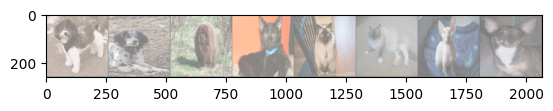

In [ ]:
grid_images = torchvision.utils.make_grid(images)
print(f"Grid Shape: {grid_images.shape}")
grid_images = grid_images / 2 + 0.5  # 正規化解除
plt.imshow(torch.permute(grid_images, (1, 2, 0)))
plt.show()

# U-Net定義

OH = ((H + 2P - FH)/S) + 1\
OW = ((W + 2P - FW)/S) + 1\
なので、カーネルサイズ3、パディング1で解像度を変えずに処理が行える\
（セグメンテーションでは入力と同じ解像度で出力を出したいので、パラメータとしては上記が一般的）

In [ ]:
# 特徴抽出⇒正規化⇒ReLuを２回繰り返すことで表現力が向上する
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)

In [ ]:
class UNet(nn.Module):
    def __init__(self, in_channels=3, num_classes=1):
        super().__init__()

        # Encoder：チャンネル数を増やしていき、情報の密度を濃くする
        self.enc1 = DoubleConv(in_channels, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.enc4 = DoubleConv(256, 512)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.center = DoubleConv(512, 1024)

        # Decoder：情報の復元と、スキップ接続後のデータを整理する
        self.up4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(1024, 512)

        self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(128, 64)

        # Output：マスク画像として出力
        self.out = nn.Conv2d(64, num_classes, kernel_size=1)

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        # Center
        c = self.center(self.pool(e4))

        # Decoder
        d4 = self.up4(c)
        d4 = torch.cat([e4, d4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([e3, d3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([e2, d2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([e1, d1], dim=1)
        d1 = self.dec1(d1)

        return self.out(d1)


In [ ]:
model = UNet(in_channels=3, num_classes=1)
model.to(device)


In [ ]:
bce = nn.BCEWithLogitsLoss() #各ピクセルで犬・猫か背景かを評価
dice = smp.losses.DiceLoss(mode='binary', from_logits=True) # 正解領域と予測領域の重なりを評価
optimizer = optim.Adam(model.parameters(), lr=1e-4)

# 学習とスコアの可視化

In [ ]:
def iou_score(pred, target, threshold=0.5, eps=1e-6):
    pred = torch.sigmoid(pred)
    pred = (pred > threshold).float()

    intersection = (pred * target).sum(dim=(1, 2, 3)) # 正解領域と予測領域の積集合
    union = pred.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3)) - intersection # 正解領域と予測領域の和集合

    iou = (intersection + eps) / (union + eps)
    return iou.mean()


In [ ]:
def train_one_epoch(model, loader, optimizer, device):
    model.train()

    running_loss = 0.0
    running_iou = 0.0

    for images, masks in loader:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss_bce = bce(outputs, masks)
        loss_dice = dice(outputs, masks)
        loss = loss_bce + loss_dice # bceとdiceを組み合わせることでピクセルごとの判定だけでなく、領域の重なりも考慮

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        running_iou += iou_score(outputs.detach(), masks).item()

    epoch_loss = running_loss / len(loader)
    epoch_iou = running_iou / len(loader)

    return epoch_loss, epoch_iou


In [ ]:
@torch.no_grad()
def validate_one_epoch(model, loader, device):
    model.eval()

    running_loss = 0.0
    running_iou = 0.0

    for images, masks in loader:
        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)

        loss_bce = bce(outputs, masks)
        loss_dice = dice(outputs, masks)
        loss = loss_bce + loss_dice

        running_loss += loss.item()
        running_iou += iou_score(outputs, masks).item()

    epoch_loss = running_loss / len(loader)
    epoch_iou = running_iou / len(loader)

    return epoch_loss, epoch_iou


In [ ]:
num_epochs = 10

history = {
    "train_loss": [],
    "val_loss": [],
    "train_iou": [],
    "val_iou": []
}
best_iou = 0.0

for epoch in range(num_epochs):
    train_loss, train_iou = train_one_epoch(
        model, train_loader, optimizer, device
    )
    val_loss, val_iou = validate_one_epoch(
        model, val_loader, device
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_iou"].append(train_iou)
    history["val_iou"].append(val_iou)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f}, Train IoU: {train_iou:.4f} | "
        f"Val Loss: {val_loss:.4f}, Val IoU: {val_iou:.4f}"
    )

    if val_iou > best_iou:
        best_iou = val_iou
        torch.save(model.state_dict(), "/content/drive/MyDrive/U-Net/output/best_model.pth")
        print(f"Epoch {epoch+1}: New best IoU {best_iou:.4f} saved!")


Epoch [1/10] Train Loss: 0.6022, Train IoU: 0.7668 | Val Loss: 0.4444, Val IoU: 0.8261
Epoch 1: New best IoU 0.8261 saved!
Epoch [2/10] Train Loss: 0.4090, Train IoU: 0.8374 | Val Loss: 0.3616, Val IoU: 0.8494
Epoch 2: New best IoU 0.8494 saved!
Epoch [3/10] Train Loss: 0.3515, Train IoU: 0.8566 | Val Loss: 0.3409, Val IoU: 0.8585
Epoch 3: New best IoU 0.8585 saved!
Epoch [4/10] Train Loss: 0.3178, Train IoU: 0.8690 | Val Loss: 0.3082, Val IoU: 0.8719
Epoch 4: New best IoU 0.8719 saved!
Epoch [5/10] Train Loss: 0.2925, Train IoU: 0.8794 | Val Loss: 0.2813, Val IoU: 0.8824
Epoch 5: New best IoU 0.8824 saved!
Epoch [6/10] Train Loss: 0.2687, Train IoU: 0.8882 | Val Loss: 0.2584, Val IoU: 0.8887
Epoch 6: New best IoU 0.8887 saved!
Epoch [7/10] Train Loss: 0.2593, Train IoU: 0.8916 | Val Loss: 0.2605, Val IoU: 0.8898
Epoch 7: New best IoU 0.8898 saved!
Epoch [8/10] Train Loss: 0.2419, Train IoU: 0.8979 | Val Loss: 0.2486, Val IoU: 0.8931
Epoch 8: New best IoU 0.8931 saved!
Epoch [9/10] Tra

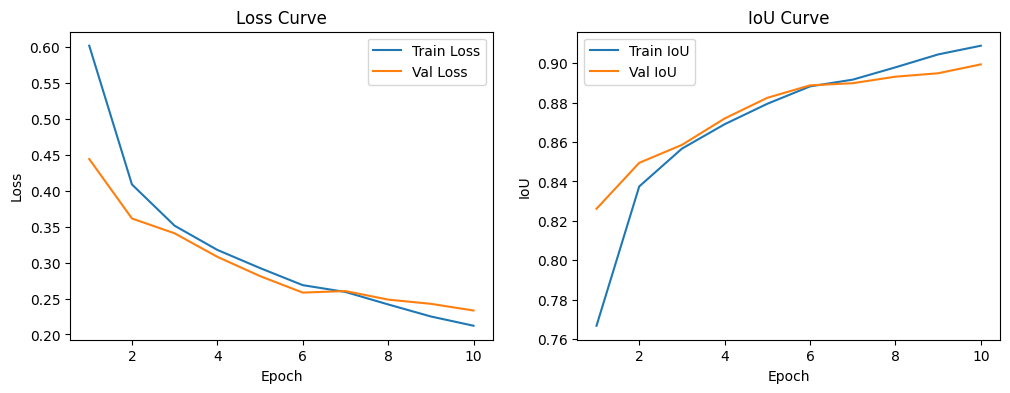

In [ ]:
epochs = range(1, num_epochs + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_loss"], label="Train Loss")
plt.plot(epochs, history["val_loss"], label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss Curve")

plt.subplot(1, 2, 2)
plt.plot(epochs, history["train_iou"], label="Train IoU")
plt.plot(epochs, history["val_iou"], label="Val IoU")
plt.xlabel("Epoch")
plt.ylabel("IoU")
plt.legend()
plt.title("IoU Curve")

plt.show()


# IoUの値が高いものと低いものを比較

In [ ]:
def get_best_worst_predictions(model, loader, device):
    model.eval()
    results = []

    with torch.no_grad():
        for images, masks in loader:
            images, masks = images.to(device), masks.to(device)
            outputs = model(images)

            # 1枚ずつIoUを計算
            for i in range(images.size(0)):
                # 単一画像のIoUを計算
                score = iou_score(outputs[i:i+1], masks[i:i+1])

                # 画像, 正解, 予測, スコアを保存
                results.append({
                    'image': images[i].cpu(),
                    'mask': masks[i].cpu(),
                    'pred': torch.sigmoid(outputs[i]).cpu(),
                    'score': score
                })

    # スコアでソート（昇順）
    results.sort(key=lambda x: x['score'])

    return results[:3], results[-3:] # スコアの良かったもの、悪かったものを３つ表示

# 推論

In [ ]:
@torch.no_grad()
def inference(model, image, device):
    model.eval()
    image = image.to(device)

    output = model(image)          # logits
    prob = torch.sigmoid(output)   # 確率に変換

    return prob

In [ ]:
# 閾値より大きければマスク画像とする
def post_process(prob, threshold=0.5):
    mask = (prob > threshold).float()
    return mask.squeeze().cpu().numpy()

In [ ]:
def visualize_result(image, gt_mask, pred_mask):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(image)
    plt.title("Input Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(gt_mask, cmap="gray")
    plt.title("Ground Truth")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(pred_mask, cmap="gray")
    plt.title("Prediction")
    plt.axis("off")

    plt.show()


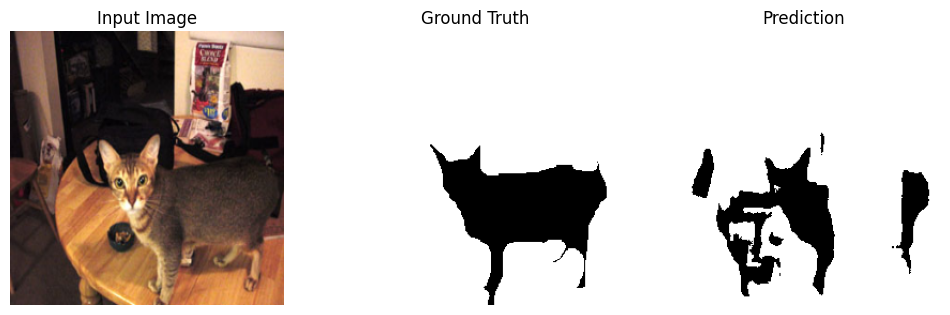

In [ ]:
# バリデーションデータセットから１枚目の画像を取得
image, gt_mask = tv_val_dataset[0]

# バッチ次元追加（モデルの入力がバッチ単位を要求するため）
image_tensor = image.unsqueeze(0)

# 推論
prob = inference(model, image_tensor, device)
pred_mask = post_process(prob, threshold=0.5)

visualize_result(
    image.permute(1, 2, 0).cpu().numpy(),
    gt_mask.squeeze().cpu().numpy(),
    pred_mask
)


# データ拡張による効果検証

In [ ]:
train_transforms = v2.Compose([
    # 元の面積の80%〜100%の範囲で切り抜く
    v2.RandomResizedCrop(size=(256, 256), scale=(0.8, 1.0), antialias=True),

    # 50%の確率で左右反転
    v2.RandomHorizontalFlip(p=0.5),

    # 明るさ、コントラスト、彩度を20%の範囲で変化
    v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),

    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True)
])

mask_transforms = v2.Compose([
    v2.Resize((256, 256)),
    v2.ToImage(),
    v2.Lambda(lambda x: (x > 1).float()) # 1（犬・猫）,2（背景）,3（境界） -> 犬・猫を0,それ以外を1に変換
])

tv_dataset_aug = OxfordIIITPet(
    root="data",
    split="trainval",
    target_types="segmentation",
    download=True,
    transform=train_transforms,
    target_transform=mask_transforms
)

tv_val_dataset_aug = OxfordIIITPet(
    root="data",
    split="test",
    target_types="segmentation",
    download=True,
    transform=train_transforms,
    target_transform=mask_transforms
)

In [ ]:
train_loader_aug = DataLoader(
    tv_dataset_aug,
    batch_size=8,
    shuffle=True,
    num_workers=4,
    pin_memory=True
)

val_loader_aug = DataLoader(
    tv_val_dataset_aug,
    batch_size=8,
    shuffle=False,
    num_workers=4,
    pin_memory=True
)

In [ ]:
model_aug = UNet(in_channels=3, num_classes=1)
model_aug.to(device)

In [ ]:
bce = nn.BCEWithLogitsLoss()
dice = smp.losses.DiceLoss(mode='binary', from_logits=True)
optimizer = optim.Adam(model_aug.parameters(), lr=1e-4)

In [ ]:
num_epochs = 10

history = {
    "train_loss": [],
    "val_loss": [],
    "train_iou": [],
    "val_iou": []
}
best_iou = 0.0

for epoch in range(num_epochs):
    train_loss, train_iou = train_one_epoch(
        model_aug, train_loader_aug, optimizer, device
    )
    val_loss, val_iou = validate_one_epoch(
        model_aug, val_loader_aug, device
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_iou"].append(train_iou)
    history["val_iou"].append(val_iou)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f}, Train IoU: {train_iou:.4f} | "
        f"Val Loss: {val_loss:.4f}, Val IoU: {val_iou:.4f}"
    )
    if val_iou > best_iou:
        best_iou = val_iou
        torch.save(model_aug.state_dict(), "/content/drive/MyDrive/U-Net/output/best_model_aug.pth")
        print(f"Epoch {epoch+1}: New best IoU {best_iou:.4f} saved!")



Epoch [1/10] Train Loss: 0.7442, Train IoU: 0.7122 | Val Loss: 0.6583, Val IoU: 0.7496
Epoch 1: New best IoU 0.7496 saved!
Epoch [2/10] Train Loss: 0.6225, Train IoU: 0.7622 | Val Loss: 0.5852, Val IoU: 0.7709
Epoch 2: New best IoU 0.7709 saved!
Epoch [3/10] Train Loss: 0.5830, Train IoU: 0.7714 | Val Loss: 0.5679, Val IoU: 0.7774
Epoch 3: New best IoU 0.7774 saved!
Epoch [4/10] Train Loss: 0.5640, Train IoU: 0.7776 | Val Loss: 0.5499, Val IoU: 0.7831
Epoch 4: New best IoU 0.7831 saved!
Epoch [5/10] Train Loss: 0.5490, Train IoU: 0.7830 | Val Loss: 0.5324, Val IoU: 0.7887
Epoch 5: New best IoU 0.7887 saved!
Epoch [6/10] Train Loss: 0.5442, Train IoU: 0.7838 | Val Loss: 0.5358, Val IoU: 0.7861
Epoch [7/10] Train Loss: 0.5365, Train IoU: 0.7869 | Val Loss: 0.5215, Val IoU: 0.7917
Epoch 7: New best IoU 0.7917 saved!
Epoch [8/10] Train Loss: 0.5314, Train IoU: 0.7878 | Val Loss: 0.5153, Val IoU: 0.7944
Epoch 8: New best IoU 0.7944 saved!
Epoch [9/10] Train Loss: 0.5252, Train IoU: 0.7899 |

## スコアの可視化

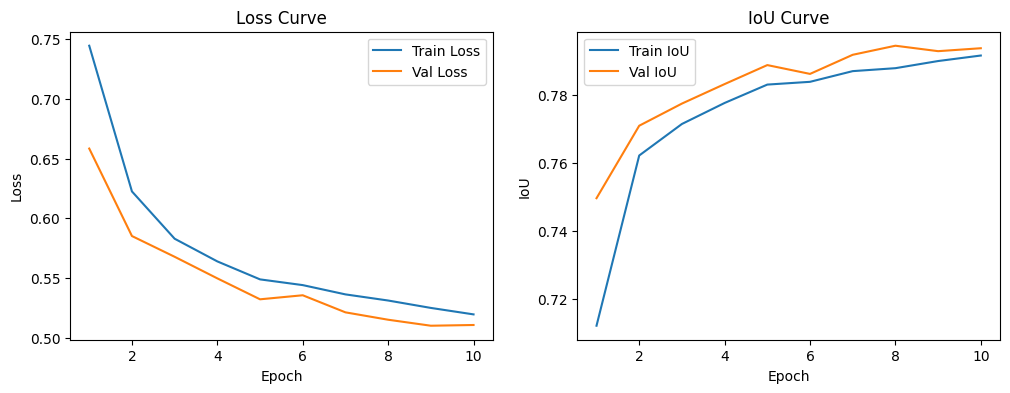

In [ ]:
epochs = range(1, num_epochs + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_loss"], label="Train Loss")
plt.plot(epochs, history["val_loss"], label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss Curve")

plt.subplot(1, 2, 2)
plt.plot(epochs, history["train_iou"], label="Train IoU")
plt.plot(epochs, history["val_iou"], label="Val IoU")
plt.xlabel("Epoch")
plt.ylabel("IoU")
plt.legend()
plt.title("IoU Curve")

plt.show()


# 学習済みモデルを使用

In [ ]:
preprocess_params = smp.encoders.get_preprocessing_params("resnet34")
mean = preprocess_params['mean']
std = preprocess_params['std']

In [ ]:
img_transforms = v2.Compose([
    v2.Resize((256, 256)),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=mean, std=std)
])

mask_transforms = v2.Compose([
    v2.Resize((256, 256)),
    v2.ToImage(),
    v2.Lambda(lambda x: (x > 1).float())
])

tv_dataset_res = OxfordIIITPet(
    root="data",
    split="trainval",
    target_types="segmentation",
    download=True,
    transform=img_transforms,
    target_transform=mask_transforms
)

tv_val_dataset_res = OxfordIIITPet(
    root="data",
    split="test",
    target_types="segmentation",
    download=True,
    transform=img_transforms,
    target_transform=mask_transforms
)

In [ ]:
train_loader_res = DataLoader(
    tv_dataset_res,
    batch_size=8,
    shuffle=True,
    num_workers=4,
    pin_memory=True
)

val_loader_res = DataLoader(
    tv_val_dataset_res,
    batch_size=8,
    shuffle=False,
    num_workers=4,
    pin_memory=True
)

In [ ]:
# モデルの定義
model_res = smp.Unet(
    encoder_name="resnet34", # エンコーダにResNet34を指定
    encoder_weights="imagenet", # ImageNetで学習済みの重みを使用
    in_channels=3,
    classes=1,
    activation=None
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_res.to(device)

Unet(
  (encoder): ResNetEncoder(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05,

In [ ]:
bce = nn.BCEWithLogitsLoss()
dice = smp.losses.DiceLoss(mode='binary', from_logits=True)
optimizer = optim.Adam(model_res.parameters(), lr=1e-4)

In [ ]:
num_epochs = 10

history = {
    "train_loss": [],
    "val_loss": [],
    "train_iou": [],
    "val_iou": []
}
best_iou = 0.0

for epoch in range(num_epochs):
    train_loss, train_iou = train_one_epoch(
        model_res, train_loader_res, optimizer, device
    )
    val_loss, val_iou = validate_one_epoch(
        model_res, val_loader_res, device
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_iou"].append(train_iou)
    history["val_iou"].append(val_iou)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f}, Train IoU: {train_iou:.4f} | "
        f"Val Loss: {val_loss:.4f}, Val IoU: {val_iou:.4f}"
    )
    if val_iou > best_iou:
        best_iou = val_iou
        torch.save(model_res.state_dict(), "/content/drive/MyDrive/U-Net/output/best_model_res.pth")
        print(f"Epoch {epoch+1}: New best IoU {best_iou:.4f} saved!")



/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch [1/10] Train Loss: 0.3124, Train IoU: 0.8950 | Val Loss: 0.1937, Val IoU: 0.9236
Epoch 1: New best IoU 0.9236 saved!
Epoch [2/10] Train Loss: 0.1656, Train IoU: 0.9351 | Val Loss: 0.1741, Val IoU: 0.9291
Epoch 2: New best IoU 0.9291 saved!
Epoch [3/10] Train Loss: 0.1309, Train IoU: 0.9444 | Val Loss: 0.1511, Val IoU: 0.9378
Epoch 3: New best IoU 0.9378 saved!
Epoch [4/10] Train Loss: 0.1164, Train IoU: 0.9490 | Val Loss: 0.1616, Val IoU: 0.9346
Epoch [5/10] Train Loss: 0.1141, Train IoU: 0.9490 | Val Loss: 0.1591, Val IoU: 0.9352
Epoch [6/10] Train Loss: 0.1024, Train IoU: 0.9535 | Val Loss: 0.1483, Val IoU: 0.9397
Epoch 6: New best IoU 0.9397 saved!
Epoch [7/10] Train Loss: 0.0933, Train IoU: 0.9574 | Val Loss: 0.1724, Val IoU: 0.9304
Epoch [8/10] Train Loss: 0.0937, Train IoU: 0.9568 | Val Loss: 0.1784, Val IoU: 0.9294
Epoch [9/10] Train Loss: 0.0862, Train IoU: 0.9597 | Val Loss: 0.1499, Val IoU: 0.9402
Epoch 9: New best IoU 0.9402 saved!
Epoch [10/10] Train Loss: 0.0757, Tra

## スコアの可視化

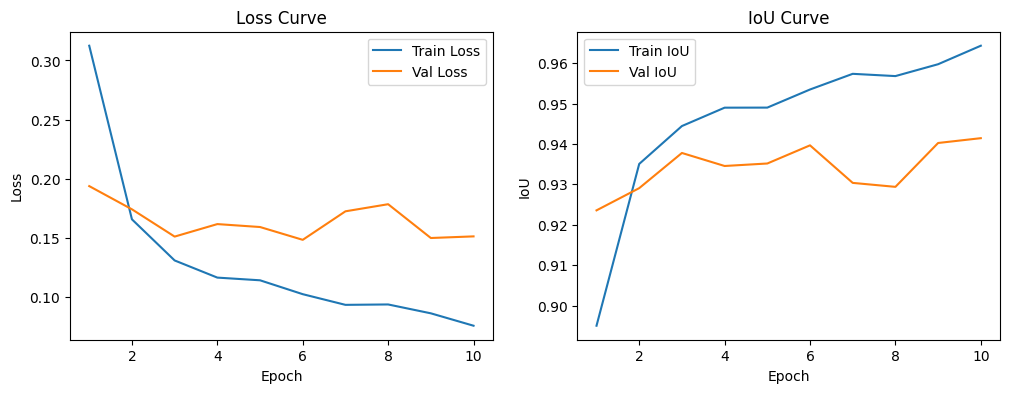

In [ ]:
epochs = range(1, num_epochs + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_loss"], label="Train Loss")
plt.plot(epochs, history["val_loss"], label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss Curve")

plt.subplot(1, 2, 2)
plt.plot(epochs, history["train_iou"], label="Train IoU")
plt.plot(epochs, history["val_iou"], label="Val IoU")
plt.xlabel("Epoch")
plt.ylabel("IoU")
plt.legend()
plt.title("IoU Curve")

plt.show()


## 推論

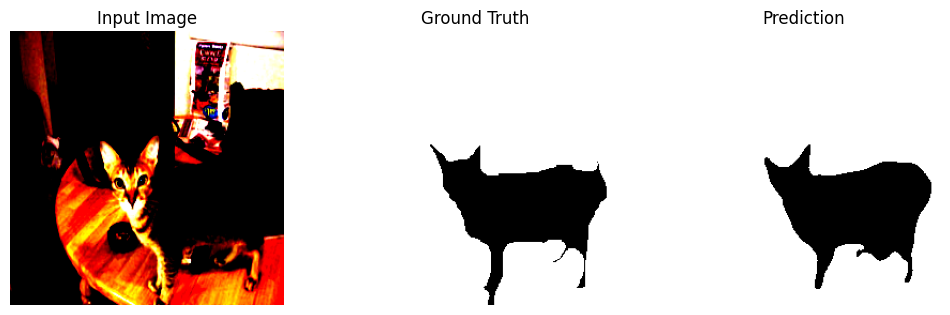

In [ ]:
image, gt_mask = tv_val_dataset_res[0]
image_tensor = image.unsqueeze(0)

prob = inference(model_res, image_tensor, device)
pred_mask = post_process(prob, threshold=0.5)

visualize_result(
    image.permute(1, 2, 0).cpu().numpy(),
    gt_mask.squeeze().cpu().numpy(),
    pred_mask
)